In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

In [2]:
ind_cell_df = pd.read_csv('h01c3/cell_positions_h01_rotated_full.csv')
ind_cell_df.rename({'Unnamed: 0': 'id_new'}, axis=1, inplace=True)

In [3]:
# Version 1:  exclude only some border neurons for correct Exc/Inh classification, focus in the good cell placement, Radius = 400 um
ind_cell_df_sub = ind_cell_df[(ind_cell_df['distance2Dcenter'] <= 400.0) & (ind_cell_df['z_new'] >= 4.0) & (ind_cell_df['z_new'] <= 170.0) & (ind_cell_df['y_new'] >= 640) & (ind_cell_df['y_new'] <= 3150)]
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='layer')
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='z_new')
ind_cell_df_sub = ind_cell_df_sub.reset_index()    
print("Ntotal:%d \t NE:%d\t N_L2E:%d \t N_L2I:%d \t N_L3E:%d \t N_L3I:%d" % (len(ind_cell_df_sub), len(ind_cell_df_sub[(ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'inhibitory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'inhibitory')])))
ind_cell_df_sub

Ntotal:7000 	 NE:4731	 N_L2E:1288 	 N_L2I:746 	 N_L3E:711 	 N_L3I:441


,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
0,955,955,8040318755,1587199,2193248,6467,1236.693906,762.913849,6.467,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
1,8751,8751,5032046272,2497272,1574056,7680,1393.958912,1852.362937,7.680,303.818696,4,excitatory,L4E,excitatory/spiny neuron with atypical tree,314,130,444,L4neuronexcitatory/spiny-with-atypical-tree
2,6409,6409,1539020057,2923840,896792,7680,1182.064963,2624.209903,7.680,112.377116,2,excitatory,L23E,pyramidal neuron,890,334,1224,L2pyramidalneuron
3,13655,13655,1347848984,2538112,637672,7680,730.533709,2514.442918,7.680,377.358316,2,inhibitory,L23I,interneuron,292,191,483,L2neuroninterneuron
4,6902,6902,2412641579,2744624,988040,7680,1128.451190,2430.379731,7.680,81.874466,3,excitatory,L23E,pyramidal neuron,7153,1955,9108,L3pyramidalneuron
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,15323,15323,102228727723,2365983,1486336,169455,1240.623808,1814.680767,169.455,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...
6996,11139,11139,101966872869,2422208,1413760,169619,1225.012591,1905.150742,169.619,151.266473,4,inhibitory,L4I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron
6997,6579,6579,100295335167,3041184,1019648,169652,1351.916881,2627.889186,169.652,265.934456,2,excitatory,L23E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
6998,10919,10919,100251999523,3054560,1042047,169785,1377.472944,2622.643214,169.785,290.298011,2,inhibitory,L23I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron


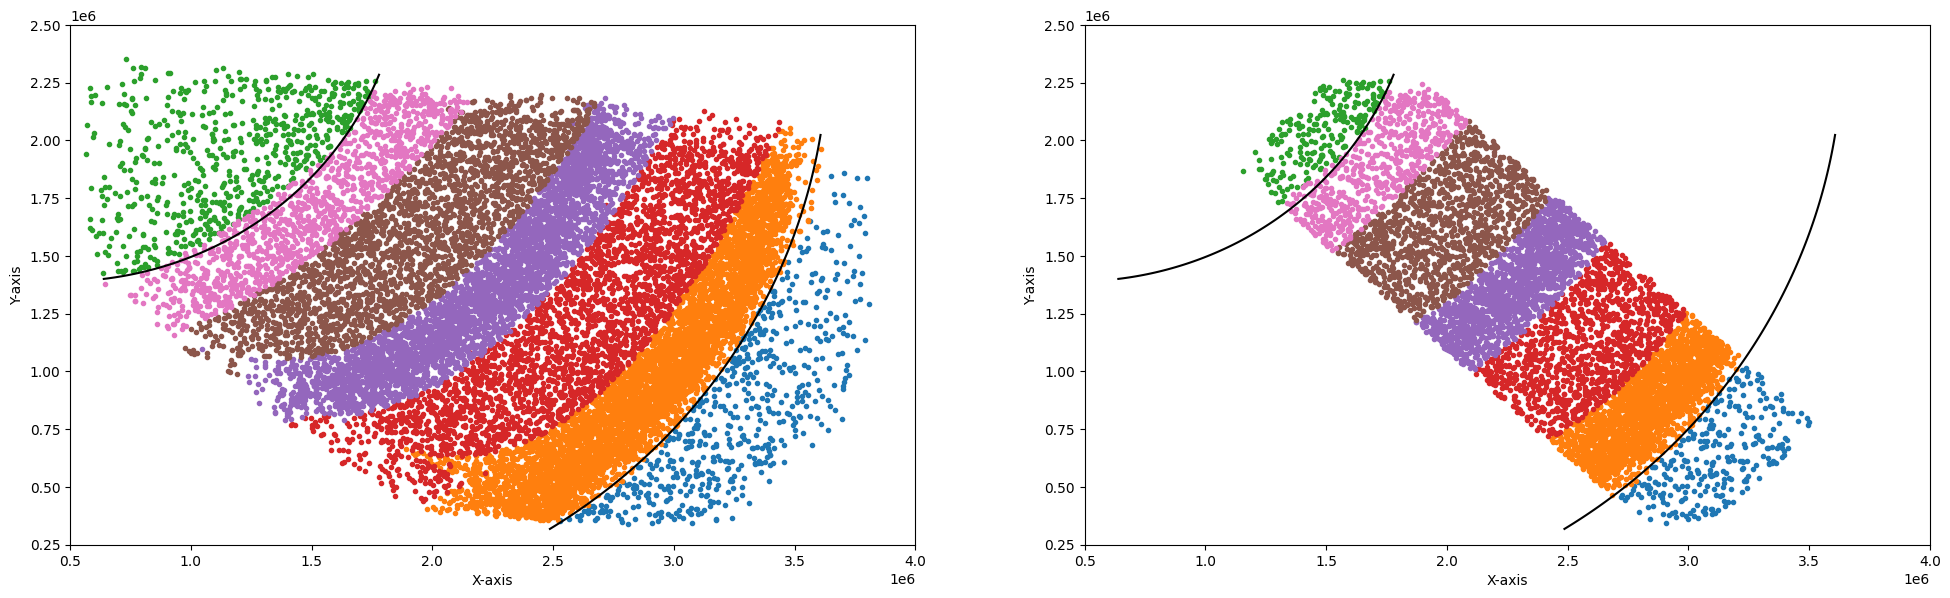

In [4]:
with open("h01c3/cortical_bounds_circles.json", "r") as f:
  bounds = json.load(f)

Fig = plt.figure(figsize=(24,6.75))

plt.subplot(121)

plt.plot(ind_cell_df[ind_cell_df['layer']==1]['x'].values,ind_cell_df[ind_cell_df['layer']==1]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==2]['x'].values,ind_cell_df[ind_cell_df['layer']==2]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==7]['x'].values,ind_cell_df[ind_cell_df['layer']==7]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==3]['x'].values,ind_cell_df[ind_cell_df['layer']==3]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==4]['x'].values,ind_cell_df[ind_cell_df['layer']==4]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==5]['x'].values,ind_cell_df[ind_cell_df['layer']==5]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==6]['x'].values,ind_cell_df[ind_cell_df['layer']==6]['y'].values, '.')
cdd = bounds[0]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.54*np.pi, 1.88*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')
cdd = bounds[5]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.68*np.pi, 1.95*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')

plt.xlim(500000,4000000)
plt.ylim(250000,2500000)
plt.xlabel('X-axis')
plt.ylabel('Y-axis');

plt.subplot(122)
ind_cell_df_2 = ind_cell_df_sub

plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==1]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==1]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==2]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==2]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==7]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==7]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==3]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==3]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==4]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==4]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==5]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==5]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==6]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==6]['y'].values, '.')

cdd = bounds[0]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.54*np.pi, 1.88*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')
cdd = bounds[5]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.68*np.pi, 1.95*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')

plt.xlim(500000,4000000)
plt.ylim(250000,2500000)
plt.xlabel('X-axis')
plt.ylabel('Y-axis');

plt.show() 


In [5]:
# #  Version 2: good morphologies only, focus on full morphology recontruction, axons and synapses
# ind_cell_df_sub = ind_cell_df[(ind_cell_df['distance2Dcenter'] <= 264.6) & (ind_cell_df['z_new'] >= 25.0) & (ind_cell_df['z_new'] <= 125.0) & (ind_cell_df['layer'] >= 2) & (ind_cell_df['layer'] <= 3)]
# ind_cell_df_sub = ind_cell_df_sub.sort_values(by='layer')
# ind_cell_df_sub = ind_cell_df_sub.sort_values(by='z_new')
# ind_cell_df_sub = ind_cell_df_sub.reset_index()    
# print("Ntotal:%d \t NE:%d\t N_L2E:%d \t N_L2I:%d \t N_L3E:%d \t N_L3I:%d" % (len(ind_cell_df_sub), len(ind_cell_df_sub[(ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'inhibitory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'inhibitory')])))
# ind_cell_df_sub

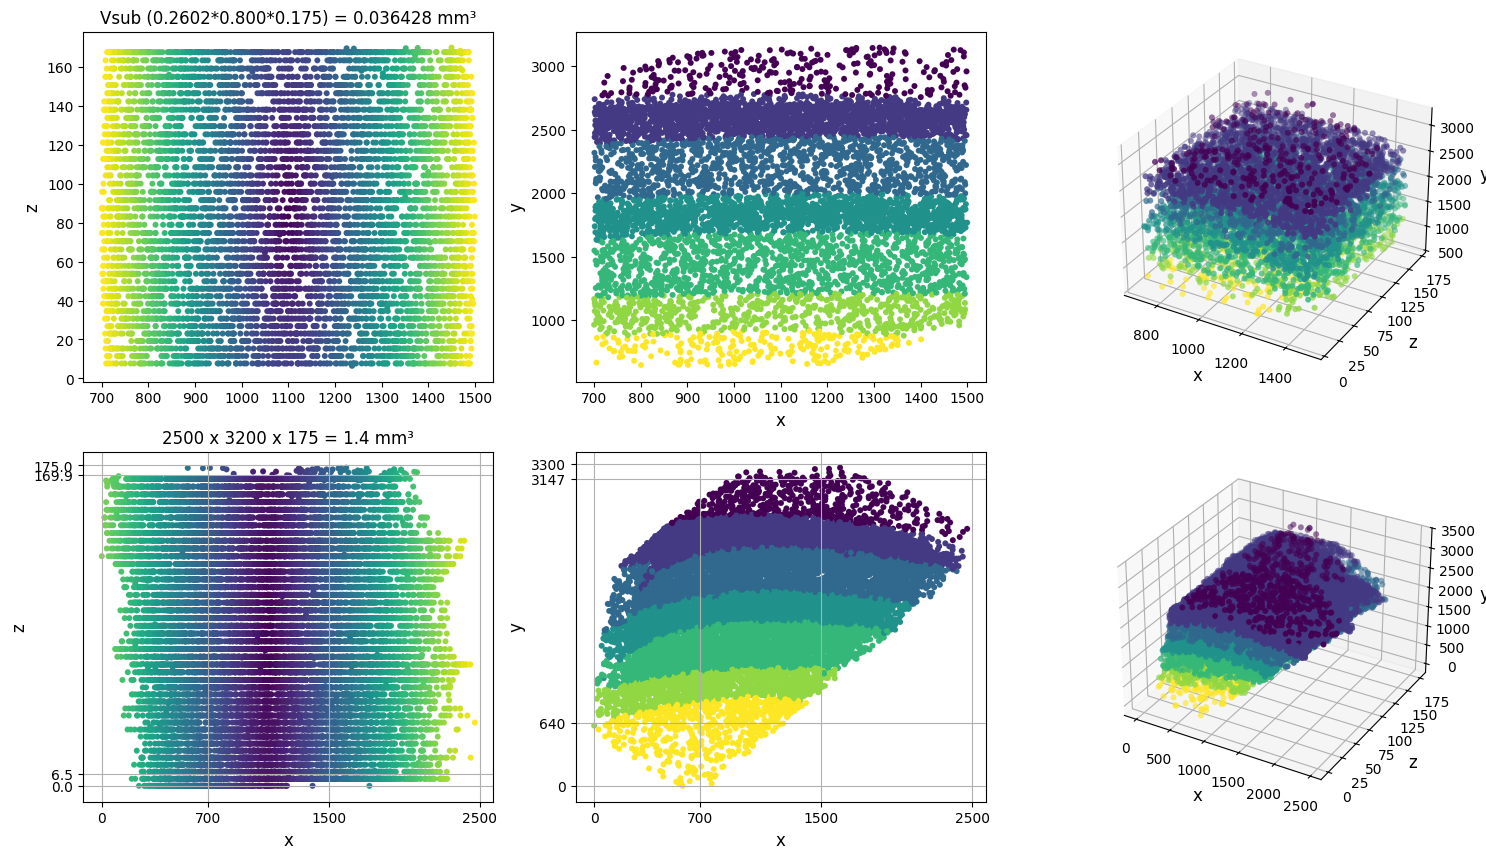

In [6]:
fig = plt.figure(figsize=(18, 10))


ax1 = fig.add_subplot(2, 3, 1)
# ax1.set_title("260.2 x 800 x 175 = 36000000 = 0.036 mm³")  # Guo 2023 π×250×250×950 = 0.186532064 mm³ 1000 L23 neurons
ax1.set_title("Vsub (0.2602*0.800*0.175) = 0.036428 mm³") 
ax1.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['z_new'], lw=0.05, s=18, c=ind_cell_df_sub['distance2Dcenter'], )
ax1.set_xlabel(' ', fontsize=12); ax1.set_ylabel('z', fontsize=12)

ax2 = fig.add_subplot(2, 3, 2)
ax2.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['y_new'], lw=0.05, s=18, c=ind_cell_df_sub['layer'], )
ax2.set_xlabel('x', fontsize=12); ax2.set_ylabel('y', fontsize=12)

ax3 = fig.add_subplot(2, 3, 3, projection='3d')
ax3.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['z_new'], ind_cell_df_sub['y_new'], lw=0.05, s=18, c=ind_cell_df_sub['layer'], );
ax3.set_xlabel('x', fontsize=12); ax3.set_ylabel('z', fontsize=12); ax3.set_zlabel('y', fontsize=12)

ax4 = fig.add_subplot(2, 3, 4)
ax4.set_title("2500 x 3200 x 175 = 1.4 mm³")
ax4.scatter(ind_cell_df['x_new'], ind_cell_df['z_new'], lw=0.05, s=18, c=ind_cell_df['distance2Dcenter'], )
ax4.set_xlabel('x', fontsize=12); ax4.set_ylabel('z', fontsize=12)
xmin = ind_cell_df_sub['x_new'].min(); xmax = ind_cell_df_sub['x_new'].max(); ymin = ind_cell_df_sub['y_new'].min(); ymax = ind_cell_df_sub['y_new'].max(); zmin = ind_cell_df_sub['z_new'].min(); zmax = ind_cell_df_sub['z_new'].max()
ax4.set_xticks([0,xmin,xmax,2500])
ax4.set_yticks([0,zmin,zmax,175])
ax4.grid(True)

ax5 = fig.add_subplot(2, 3, 5)
ax5.scatter(ind_cell_df['x_new'], ind_cell_df['y_new'], lw=0.05, s=18, c=ind_cell_df['layer'], )
ax5.set_xlabel('x', fontsize=12); ax5.set_ylabel('y', fontsize=12)
ax5.set_xticks([0,xmin,xmax,2500])
ax5.set_yticks([0,ymin,ymax,3300])
ax5.grid(True)

ax6 = fig.add_subplot(2, 3, 6, projection='3d')
ax6.scatter(ind_cell_df['x_new'], ind_cell_df['z_new'], ind_cell_df['y_new'], lw=0.05, s=18, c=ind_cell_df['layer'], );
ax6.set_xlabel('x', fontsize=12); ax6.set_ylabel('z', fontsize=12); ax6.set_zlabel('y', fontsize=12);

# Replicating the table 5 times with Z+= Zmax-Zmin=167.282

In [7]:
ind_cell_df_sub['id_new'] = [z for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub0 = ind_cell_df_sub.copy()
ind_cell_df_sub1 = ind_cell_df_sub.copy()
ind_cell_df_sub2 = ind_cell_df_sub.copy()
ind_cell_df_sub3 = ind_cell_df_sub.copy()
ind_cell_df_sub0['z_new'] = [z-2*167.282 for z in ind_cell_df_sub['z_new'].values]
ind_cell_df_sub1['z_new'] = [z-167.282 for z in ind_cell_df_sub['z_new'].values]
ind_cell_df_sub2['z_new'] = [z+167.282 for z in ind_cell_df_sub['z_new'].values]
ind_cell_df_sub3['z_new'] = [z+2*167.282 for z in ind_cell_df_sub['z_new'].values]

ind_cell_df_sub0['id_new'] = [z+ind_cell_df_sub['id_new'].size for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub1['id_new'] = [z+2*ind_cell_df_sub['id_new'].size for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub2['id_new'] = [z+3*ind_cell_df_sub['id_new'].size for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub3['id_new'] = [z+4*ind_cell_df_sub['id_new'].size for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub3 = pd.concat([ind_cell_df_sub0, ind_cell_df_sub1, ind_cell_df_sub, ind_cell_df_sub2, ind_cell_df_sub3], ignore_index=True)
ind_cell_df_sub3

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
0,955,7000,8040318755,1587199,2193248,6467,1236.693906,762.913849,-328.097,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
1,8751,7001,5032046272,2497272,1574056,7680,1393.958912,1852.362937,-326.884,303.818696,4,excitatory,L4E,excitatory/spiny neuron with atypical tree,314,130,444,L4neuronexcitatory/spiny-with-atypical-tree
2,6409,7002,1539020057,2923840,896792,7680,1182.064963,2624.209903,-326.884,112.377116,2,excitatory,L23E,pyramidal neuron,890,334,1224,L2pyramidalneuron
3,13655,7003,1347848984,2538112,637672,7680,730.533709,2514.442918,-326.884,377.358316,2,inhibitory,L23I,interneuron,292,191,483,L2neuroninterneuron
4,6902,7004,2412641579,2744624,988040,7680,1128.451190,2430.379731,-326.884,81.874466,3,excitatory,L23E,pyramidal neuron,7153,1955,9108,L3pyramidalneuron
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34995,15323,34995,102228727723,2365983,1486336,169455,1240.623808,1814.680767,504.019,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...
34996,11139,34996,101966872869,2422208,1413760,169619,1225.012591,1905.150742,504.183,151.266473,4,inhibitory,L4I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron
34997,6579,34997,100295335167,3041184,1019648,169652,1351.916881,2627.889186,504.216,265.934456,2,excitatory,L23E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
34998,10919,34998,100251999523,3054560,1042047,169785,1377.472944,2622.643214,504.349,290.298011,2,inhibitory,L23I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron


Text(0.5, 0, 'z (um)')

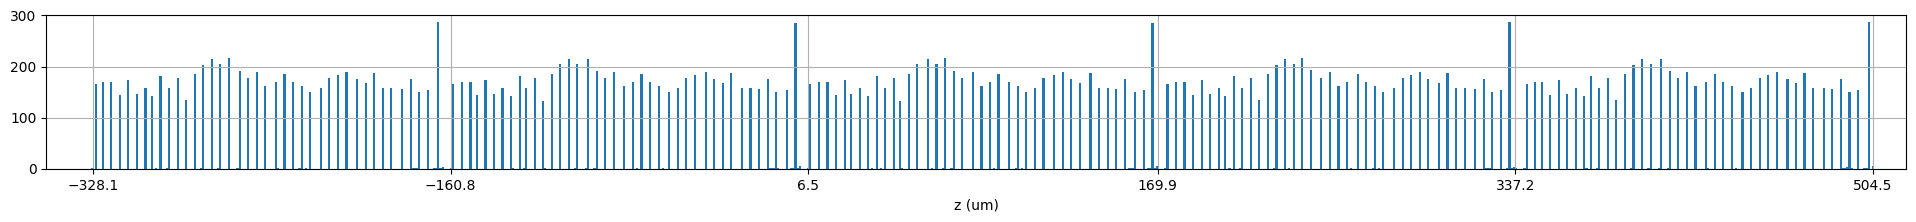

In [8]:
ind_cell_df_sub3['z_new'].hist(bins=range(-500,520,1), figsize=(24,2))
plt.xlim(-350, 520)
plt.xticks([ind_cell_df_sub3['z_new'].min(),ind_cell_df_sub1['z_new'].min(),ind_cell_df_sub['z_new'].min(),ind_cell_df_sub['z_new'].max(),ind_cell_df_sub2['z_new'].max(),ind_cell_df_sub3['z_new'].max()]);
plt.xlabel('z (um)')

In [9]:
def distance2Dmean(gidpre, mean_x, mean_z):
    return np.sqrt(np.power(ind_cell_df_sub3['x_new'][gidpre]-mean_x,2)+np.power(ind_cell_df_sub3['z_new'][gidpre]-mean_z,2))

In [10]:
mean_z = ind_cell_df_sub['z_new'].mean()
mean_x = 1100.0
mean_x, mean_z

(1100.0, 87.40899057142857)

In [11]:
ind_cell_df_sub3['distance2Dcenter_new'] = [distance2Dmean(gidpre, mean_x, mean_z) for gidpre in range(ind_cell_df_sub3['id_new'].size)]
ind_cell_df_sub3

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,distance2Dcenter_new
0,955,7000,8040318755,1587199,2193248,6467,1236.693906,762.913849,-328.097,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron,437.413365
1,8751,7001,5032046272,2497272,1574056,7680,1393.958912,1852.362937,-326.884,303.818696,4,excitatory,L4E,excitatory/spiny neuron with atypical tree,314,130,444,L4neuronexcitatory/spiny-with-atypical-tree,507.986736
2,6409,7002,1539020057,2923840,896792,7680,1182.064963,2624.209903,-326.884,112.377116,2,excitatory,L23E,pyramidal neuron,890,334,1224,L2pyramidalneuron,422.342681
3,13655,7003,1347848984,2538112,637672,7680,730.533709,2514.442918,-326.884,377.358316,2,inhibitory,L23I,interneuron,292,191,483,L2neuroninterneuron,555.107217
4,6902,7004,2412641579,2744624,988040,7680,1128.451190,2430.379731,-326.884,81.874466,3,excitatory,L23E,pyramidal neuron,7153,1955,9108,L3pyramidalneuron,415.268771
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34995,15323,34995,102228727723,2365983,1486336,169455,1240.623808,1814.680767,504.019,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...,439.703258
34996,11139,34996,101966872869,2422208,1413760,169619,1225.012591,1905.150742,504.183,151.266473,4,inhibitory,L4I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron,435.119205
34997,6579,34997,100295335167,3041184,1019648,169652,1351.916881,2627.889186,504.216,265.934456,2,excitatory,L23E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron,487.021763
34998,10919,34998,100251999523,3054560,1042047,169785,1377.472944,2622.643214,504.349,290.298011,2,inhibitory,L23I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron,500.829518


In [12]:
ind_cell_df_sub['y_new'].min(), ind_cell_df_sub['y_new'].max(), ind_cell_df_sub3['z_new'].min(), ind_cell_df_sub3['z_new'].max()

(640.388902839393, 3146.75194428238, -328.09700000000004, 504.51300000000003)

In [13]:
ind_cell_df_cylinder = ind_cell_df_sub3[(ind_cell_df_sub3['distance2Dcenter_new'] < 400) & (ind_cell_df_sub3['y_new'] >= 650.0) & (ind_cell_df_sub3['y_new'] <= 3250)]
ind_cell_df_cylinder

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,distance2Dcenter_new
668,5287,7668,3139317430,2357424,1310888,23040,1105.378963,1926.770415,-311.524,61.647233,4,excitatory,L4E,pyramidal neuron,862,260,1122,L4pyramidalneuron,398.969252
674,6225,7674,3487083954,2302000,1316632,23040,1072.213327,1881.994820,-311.524,67.405840,4,excitatory,L4E,pyramidal neuron,743,266,1009,L4pyramidalneuron,399.899525
681,7199,7681,1946459333,2893936,793376,23040,1085.569567,2671.935755,-311.524,63.084749,2,excitatory,L23E,pyramidal neuron,381,204,585,L2pyramidalneuronbipolar,399.193898
689,12955,7689,6047413032,1931368,1718600,23040,1118.707572,1337.215381,-311.524,64.198297,5,inhibitory,L5I,interneuron,50,63,113,L5neuroninterneuron,399.371386
692,7804,7692,4083797526,2329664,1317792,23040,1091.739091,1901.626098,-311.524,61.965238,4,excitatory,L4E,pyramidal neuron,438,207,645,L4pyramidalneuron,399.018513
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34195,4136,34195,28790035409,2854256,865512,150741,1112.021915,2593.971801,485.305,67.370189,2,excitatory,L23E,pyramidal neuron,2898,892,3790,L2pyramidalneuron,398.077581
34206,2843,34206,31931206276,2111136,1548864,150741,1114.775118,1584.422540,485.305,67.915537,5,excitatory,L5E,pyramidal neuron,404,313,717,L5pyramidalneuron,398.170238
34211,10471,34211,4315924195,2256680,1352048,150741,1067.762535,1824.650371,485.305,73.712076,4,excitatory,L4E,unclassified neuron,536,185,721,L4neuronexcitatory/spiny-with-atypical-treespa...,399.199810
34216,4516,34216,30824975205,2271160,1344712,150741,1072.121272,1840.286506,485.305,71.912721,4,excitatory,L4E,pyramidal neuron,228,110,338,L4pyramidalneuronsparsely-spiny,398.871480


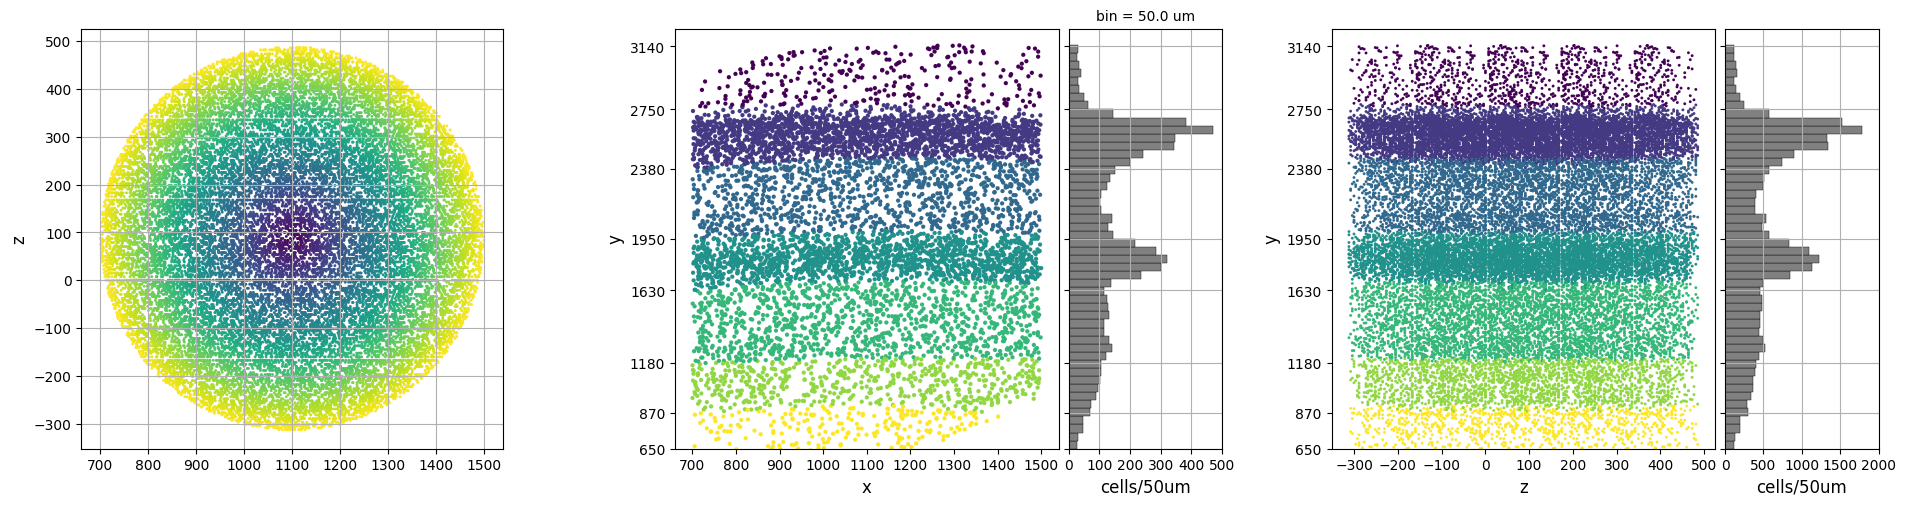

In [14]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig = plt.figure(figsize=(24, 12))
lmin = [ind_cell_df_cylinder[ind_cell_df_cylinder['layer'] == 1]['y_new'].max()]
for layer in range(1,8):
    lmin.append(ind_cell_df_cylinder[ind_cell_df_cylinder['layer'] == layer]['y_new'].min())

lmin = [10*int(l/10) for l in lmin]

ax1 = fig.add_subplot(2, 3, 1)
ax1.scatter(ind_cell_df_cylinder['x_new'], ind_cell_df_cylinder['z_new'], lw=0.05, s=4, c=ind_cell_df_cylinder['distance2Dcenter_new'], )
ax1.set_xlabel(' ', fontsize=12); ax1.set_ylabel('z', fontsize=12)
ax1.grid(True)
ax1.set_aspect('equal')

ax2 = fig.add_subplot(2, 3, 2)
ax2.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['y_new'], lw=0.05, s=9, c=ind_cell_df_sub['layer'], )
ax2.set_xlabel('x', fontsize=12); ax2.set_ylabel('y', fontsize=12)

ax2h = make_axes_locatable(ax2).append_axes('right', size='40%', pad=0.1, sharey=ax2)
ybins = np.linspace(650, 3250, 53)  # ~50 um bins
dy = ybins[1] - ybins[0]
ax2h.hist(ind_cell_df_sub['y_new'], bins=ybins, orientation='horizontal', color='gray', edgecolor='k', lw=0.3)  # 1e9: um³ -> mm³
ax2h.set_xlabel('cells/50um', fontsize=12); ax2h.set_title('bin = %.1f um' % dy, fontsize=10)
ax2h.tick_params(labelleft=False)
ax2h.set_ylim([650,3250])
ax2h.set_yticks(lmin)
ax2h.set_xticks([0,100,200,300,400,500])
ax2h.grid(True)

ax3 = fig.add_subplot(2, 3, 3)
ax3.scatter(ind_cell_df_cylinder['z_new'], ind_cell_df_cylinder['y_new'], lw=0.05, s=4, c=ind_cell_df_cylinder['layer']);
ax3.set_xlabel('z', fontsize=12); ax3.set_ylabel('y', fontsize=12)
ax3h = make_axes_locatable(ax3).append_axes('right', size='40%', pad=0.1, sharey=ax3)
ybins = np.linspace(650, 3250, 53)  # ~50 um bins
dy = ybins[1] - ybins[0]
ax3h.hist(ind_cell_df_cylinder['y_new'], bins=ybins, orientation='horizontal', color='gray', edgecolor='k', lw=0.3)  # 1e9: um³ -> mm³
ax3h.set_xlabel('cells/50um', fontsize=12); ax2h.set_title('bin = %.1f um' % dy, fontsize=10)
ax3h.tick_params(labelleft=False)
ax3h.set_ylim([650,3250])
ax3h.set_yticks(lmin)
ax3h.set_xticks([0,500,1000,1500,2000])
ax3h.grid(True)

In [15]:
ind_cell_df_cylinder['x_n'] = ind_cell_df_cylinder['x_new'] - ind_cell_df_cylinder['x_new'].min()
ind_cell_df_cylinder['y_n'] = ind_cell_df_cylinder['y_new'] - ind_cell_df_cylinder['y_new'].min()
ind_cell_df_cylinder['z_n'] = ind_cell_df_cylinder['z_new'] - ind_cell_df_cylinder['z_new'].min()
ind_cell_df_cylinder

/tmp/ipykernel_2647384/3969669749.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ind_cell_df_cylinder['x_n'] = ind_cell_df_cylinder['x_new'] - ind_cell_df_cylinder['x_new'].min()
/tmp/ipykernel_2647384/3969669749.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ind_cell_df_cylinder['y_n'] = ind_cell_df_cylinder['y_new'] - ind_cell_df_cylinder['y_new'].min()
/tmp/ipykernel_2647384/3969669749.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,...,mtype,type,Esyns,Isyns,syns,info,distance2Dcenter_new,x_n,y_n,z_n
668,5287,7668,3139317430,2357424,1310888,23040,1105.378963,1926.770415,-311.524,61.647233,...,L4E,pyramidal neuron,862,260,1122,L4pyramidalneuron,398.969252,405.335041,1275.632912,0.000
674,6225,7674,3487083954,2302000,1316632,23040,1072.213327,1881.994820,-311.524,67.405840,...,L4E,pyramidal neuron,743,266,1009,L4pyramidalneuron,399.899525,372.169405,1230.857317,0.000
681,7199,7681,1946459333,2893936,793376,23040,1085.569567,2671.935755,-311.524,63.084749,...,L23E,pyramidal neuron,381,204,585,L2pyramidalneuronbipolar,399.193898,385.525645,2020.798252,0.000
689,12955,7689,6047413032,1931368,1718600,23040,1118.707572,1337.215381,-311.524,64.198297,...,L5I,interneuron,50,63,113,L5neuroninterneuron,399.371386,418.663649,686.077878,0.000
692,7804,7692,4083797526,2329664,1317792,23040,1091.739091,1901.626098,-311.524,61.965238,...,L4E,pyramidal neuron,438,207,645,L4pyramidalneuron,399.018513,391.695168,1250.488595,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34195,4136,34195,28790035409,2854256,865512,150741,1112.021915,2593.971801,485.305,67.370189,...,L23E,pyramidal neuron,2898,892,3790,L2pyramidalneuron,398.077581,411.977992,1942.834297,796.829
34206,2843,34206,31931206276,2111136,1548864,150741,1114.775118,1584.422540,485.305,67.915537,...,L5E,pyramidal neuron,404,313,717,L5pyramidalneuron,398.170238,414.731196,933.285037,796.829
34211,10471,34211,4315924195,2256680,1352048,150741,1067.762535,1824.650371,485.305,73.712076,...,L4E,unclassified neuron,536,185,721,L4neuronexcitatory/spiny-with-atypical-treespa...,399.199810,367.718613,1173.512868,796.829
34216,4516,34216,30824975205,2271160,1344712,150741,1072.121272,1840.286506,485.305,71.912721,...,L4E,pyramidal neuron,228,110,338,L4pyramidalneuronsparsely-spiny,398.871480,372.077349,1189.149003,796.829


In [16]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

df_plot = ind_cell_df_cylinder

fig = go.Figure()

cores_por_layer = {
    1: "#EEFF00",  
    2: "#ee0d0d",
    3: "#6b13e7",
    4: "#0B8622",  
    5: "#e01acf",  
    6: "#1e1c1e",  
    7: "#002fff",  
}

for layer in range(1,8):
    df_layer = df_plot[df_plot['layer'] == layer]
    
    if len(df_layer) == 0:
        continue
        
    cor_fixa = cores_por_layer[layer]
    nome_anat = "L"+str(layer)

    fig.add_trace(go.Scatter3d(
        x=df_layer['z_n'], 
        y=df_layer['x_n'], 
        z=df_layer['y_n'],
        mode='markers',
        marker=dict(size=2.5, color=cor_fixa, opacity=0.75),
        name=nome_anat # Nome que aparecerá na legenda
    ))

camera_diagonal_com_zoom = dict(
    up=dict(x=0, y=0, z=1),       
    center=dict(x=0, y=0, z=0),   
    eye=dict(x=1.12, y=-1.26, z=0.42)  
)

eixo_limpo = dict(
    showbackground=False, 
    showgrid=False,       
    zeroline=False,       
    showline=False        
)

fig.update_layout(
    title='', 
    scene=dict(
        xaxis_title='Z (µm)',
        yaxis_title='X (µm)',
        zaxis_title='Y (µm)',
        aspectmode='data',
        xaxis=eixo_limpo,
        yaxis=eixo_limpo, 
        zaxis=eixo_limpo
    ),
    scene_camera=camera_diagonal_com_zoom, 
    width=600,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0), 
    showlegend=True,
    legend=dict(
        itemsizing='constant', # Garante que as bolinhas de cor na legenda fiquem bem visíveis
        title="Cortex",
        x=0.95, y=0.95 # Posição da legenda
    ),
    paper_bgcolor='white',
    plot_bgcolor='white'
)

# =====================================================================
# fig.write_image("cortex_visao_diagonal_zoom.png", width=1920, height=1080, scale=2)
# print(" Imagem limpa salva com sucesso: 'cortex_visao_diagonal_zoom.png'")

fig.show()

In [17]:
# ind_cell_df_cylinder.to_csv('cylinder_Gustavo.csv', columns=['x_new', 'y_new', 'z_new', 'layer'], header=False, index=False)

# Connection matrix

In [18]:
ind_cell_df = ind_cell_df_sub
N_population = ind_cell_df['mtype'].value_counts()
ind_cell_df

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
0,955,0,8040318755,1587199,2193248,6467,1236.693906,762.913849,6.467,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
1,8751,1,5032046272,2497272,1574056,7680,1393.958912,1852.362937,7.680,303.818696,4,excitatory,L4E,excitatory/spiny neuron with atypical tree,314,130,444,L4neuronexcitatory/spiny-with-atypical-tree
2,6409,2,1539020057,2923840,896792,7680,1182.064963,2624.209903,7.680,112.377116,2,excitatory,L23E,pyramidal neuron,890,334,1224,L2pyramidalneuron
3,13655,3,1347848984,2538112,637672,7680,730.533709,2514.442918,7.680,377.358316,2,inhibitory,L23I,interneuron,292,191,483,L2neuroninterneuron
4,6902,4,2412641579,2744624,988040,7680,1128.451190,2430.379731,7.680,81.874466,3,excitatory,L23E,pyramidal neuron,7153,1955,9108,L3pyramidalneuron
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,15323,6995,102228727723,2365983,1486336,169455,1240.623808,1814.680767,169.455,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...
6996,11139,6996,101966872869,2422208,1413760,169619,1225.012591,1905.150742,169.619,151.266473,4,inhibitory,L4I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron
6997,6579,6997,100295335167,3041184,1019648,169652,1351.916881,2627.889186,169.652,265.934456,2,excitatory,L23E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
6998,10919,6998,100251999523,3054560,1042047,169785,1377.472944,2622.643214,169.785,290.298011,2,inhibitory,L23I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron


In [19]:
N_population

L23E    1999
L4E     1203
L23I    1187
L5E      872
L6E      490
L4I      349
L5I      301
L1I      281
L7E      167
L6I       94
L7I       57
Name: mtype, dtype: int64

In [20]:
edges_pre_post = np.loadtxt('h01c3/edges_pre_post.txt')

In [21]:
c1, c2 = np.unique([str(a)[:-2]+', '+str(b)[:-2] for a,b in edges_pre_post],return_counts=True)
c1[c2>15], c2[c2>15]

(array(['1524667312, 2557789796', '30973073563, 31103708188',
        '36095615295, 36678107375', '37101492779, 37770758892',
        '38209095765, 39038491013', '4159329415, 3997929684',
        '4590715045, 4896065848', '4698865343, 4406144858',
        '5071249782, 5287898185', '5071249782, 5318268259',
        '5071249782, 6117557133', '5071249782, 6219969344',
        '5175470732, 6063256489', '7197958715, 7037711560',
        '7372659407, 33008496925'], dtype='<U24'),
 array([23, 20, 16, 21, 18, 17, 16, 24, 20, 30, 20, 18, 21, 20, 19]))

In [22]:
List_cell_df = set(ind_cell_df["id"].values)

index_pre_post_ = []
index_pre_post_unique = []

for a, b in edges_pre_post:

    if a in List_cell_df and b in List_cell_df and str(a)+'->'+str(b) not in index_pre_post_unique:

        index_pre_post_unique.append(str(a)+'->'+str(b))

        pre_index = ind_cell_df.index[ind_cell_df["id"] == a][0]
        post_index = ind_cell_df.index[ind_cell_df["id"] == b][0]

        mtype_pre = ind_cell_df.loc[pre_index, "mtype"]
        mtype_post = ind_cell_df.loc[post_index, "mtype"]

        x_pre = ind_cell_df.loc[pre_index, "x_new"]
        y_pre = ind_cell_df.loc[pre_index, "y_new"]
        z_pre = ind_cell_df.loc[pre_index, "z_new"]

        x_post = ind_cell_df.loc[post_index, "x_new"]
        y_post = ind_cell_df.loc[post_index, "y_new"]
        z_post = ind_cell_df.loc[post_index, "z_new"]

        distance = np.sqrt(
            (x_pre - x_post)**2 +
            (y_pre - y_post)**2 +
            (z_pre - z_post)**2
        )

        population_conn = mtype_pre + "->" + mtype_post
        
        type_pre = ind_cell_df.loc[pre_index, "EI"]
        type_post = ind_cell_df.loc[post_index, "EI"]
        general_conn = ind_cell_df.loc[pre_index, 'EI'] + "->" + ind_cell_df.loc[post_index, 'EI']

        index_pre_post_.append([pre_index,post_index,mtype_pre,mtype_post,population_conn,distance, general_conn, type_pre, type_post, int(a), int(b)])

index_pre_post_unique = pd.DataFrame(index_pre_post_, columns=["pre", "post", "mtype pre", "mtype post", "population conn", "distance", 'General conn', 'type pre', 'type post', "id_pre", "id_post"])

In [23]:
index_pre_post_unique

,pre,post,mtype pre,mtype post,population conn,distance,General conn,type pre,type post,id_pre,id_post
0,4536,2574,L23E,L23E,L23E->L23E,101.968727,excitatory->excitatory,excitatory,excitatory,28583810831,2133731762
1,3834,3803,L23E,L23E,L23E->L23E,197.415353,excitatory->excitatory,excitatory,excitatory,4229311266,4128345172
2,6091,5899,L23I,L23I,L23I->L23I,83.666395,inhibitory->inhibitory,inhibitory,inhibitory,55355122544,37857138588
3,5567,3294,L23E,L23E,L23E->L23E,316.633079,excitatory->excitatory,excitatory,excitatory,3474687797,3808378864
4,3596,2797,L23I,L4I,L23I->L4I,300.868168,inhibitory->inhibitory,inhibitory,inhibitory,31044911156,5059509351
...,...,...,...,...,...,...,...,...,...,...,...
16218,1540,1900,L23E,L23I,L23E->L23I,101.346055,excitatory->inhibitory,excitatory,inhibitory,2339824866,3038264050
16219,3199,1863,L23E,L23E,L23E->L23E,170.866071,excitatory->excitatory,excitatory,excitatory,4012121203,3007645402
16220,4394,745,L23E,L23E,L23E->L23E,97.225756,excitatory->excitatory,excitatory,excitatory,4100559981,3430549988
16221,1132,842,L23I,L23E,L23I->L23E,83.785389,inhibitory->excitatory,inhibitory,excitatory,2499384877,2251780890


In [24]:
Kout = []

aa, bb = np.unique([index_pre_post_unique["id_pre"].values], return_counts=True)

for i,id in enumerate(ind_cell_df["id"].values):
    for ii,id2 in enumerate(aa):
        if id == id2:
            Kout.append(bb[ii])
    if len(Kout) == i:
        Kout.append(0)

    # print(i,Kout[i])

In [25]:
ind_cell_df["Kout"] = Kout
ind_cell_df

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,Kout
0,955,0,8040318755,1587199,2193248,6467,1236.693906,762.913849,6.467,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron,0
1,8751,1,5032046272,2497272,1574056,7680,1393.958912,1852.362937,7.680,303.818696,4,excitatory,L4E,excitatory/spiny neuron with atypical tree,314,130,444,L4neuronexcitatory/spiny-with-atypical-tree,1
2,6409,2,1539020057,2923840,896792,7680,1182.064963,2624.209903,7.680,112.377116,2,excitatory,L23E,pyramidal neuron,890,334,1224,L2pyramidalneuron,0
3,13655,3,1347848984,2538112,637672,7680,730.533709,2514.442918,7.680,377.358316,2,inhibitory,L23I,interneuron,292,191,483,L2neuroninterneuron,0
4,6902,4,2412641579,2744624,988040,7680,1128.451190,2430.379731,7.680,81.874466,3,excitatory,L23E,pyramidal neuron,7153,1955,9108,L3pyramidalneuron,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,15323,6995,102228727723,2365983,1486336,169455,1240.623808,1814.680767,169.455,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...,0
6996,11139,6996,101966872869,2422208,1413760,169619,1225.012591,1905.150742,169.619,151.266473,4,inhibitory,L4I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron,0
6997,6579,6997,100295335167,3041184,1019648,169652,1351.916881,2627.889186,169.652,265.934456,2,excitatory,L23E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron,0
6998,10919,6998,100251999523,3054560,1042047,169785,1377.472944,2622.643214,169.785,290.298011,2,inhibitory,L23I,interneuron,0,0,0,layer-unclassifiedneuroninterneuron,0


In [26]:
ind_cell_df[(ind_cell_df['Kout'] >= 1) & (ind_cell_df['syns'] >= 500) & (ind_cell_df['layer'] >= 2) & (ind_cell_df['layer'] <= 6)]['mtype'].value_counts()

L23E    1275
L4E      517
L23I     326
L5E      287
L6E      146
L4I       81
L5I       53
L6I       16
Name: mtype, dtype: int64

In [27]:
ind_cell_df = ind_cell_df[(ind_cell_df['Kout'] >= 1) & (ind_cell_df['syns'] >= 500)]
ind_cell_df

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,Kout
4,6902,4,2412641579,2744624,988040,7680,1128.451190,2430.379731,7.680,81.874466,3,excitatory,L23E,pyramidal neuron,7153,1955,9108,L3pyramidalneuron,3
5,6440,5,1698740240,2813208,801472,7680,1037.062489,2606.900237,7.680,99.272797,2,excitatory,L23E,pyramidal neuron,578,250,828,L2pyramidalneuron,1
6,13859,6,3882494653,2976960,1245824,7680,1475.476026,2427.855581,7.680,383.244313,3,inhibitory,L23I,interneuron,836,558,1394,L3neuroninterneuron,2
8,7923,8,4387645213,1746184,1457536,7680,801.084064,1376.748063,7.680,308.617393,5,excitatory,L5E,pyramidal neuron,567,201,768,L5pyramidalneuronbipolar,1
13,6073,13,3355982557,2557216,1185472,7680,1147.665340,2158.843418,7.680,90.365605,3,excitatory,L23E,pyramidal neuron,3061,802,3863,L3pyramidalneuron,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6959,9588,6959,3137084591,2386872,1044392,167637,928.596946,2128.352709,167.637,190.522260,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1181,283,1464,L3neuronexcitatory/spiny-with-atypical-tree,1
6966,4192,6966,28380053119,2450784,730432,167637,740.048672,2387.399372,167.637,369.438334,3,excitatory,L23E,pyramidal neuron,2347,630,2977,L3pyramidalneuron,6
6968,9450,6968,3648951090,2726448,1098160,167637,1197.445651,2342.649772,167.637,128.122518,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1490,388,1878,L3neuronexcitatory/spiny-with-atypical-tree,2
6977,9848,6977,28919589274,2620136,854496,167637,945.890950,2428.641739,167.637,175.126594,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1797,553,2350,L3neuronexcitatory/spiny-with-atypical-tree,4


In [28]:
index_pre_post_unique[(index_pre_post_unique.isin(ind_cell_df['id'].values)['id_pre']) & (index_pre_post_unique.isin(ind_cell_df['id'].values)['id_post'])]

,pre,post,mtype pre,mtype post,population conn,distance,General conn,type pre,type post,id_pre,id_post
0,4536,2574,L23E,L23E,L23E->L23E,101.968727,excitatory->excitatory,excitatory,excitatory,28583810831,2133731762
1,3834,3803,L23E,L23E,L23E->L23E,197.415353,excitatory->excitatory,excitatory,excitatory,4229311266,4128345172
3,5567,3294,L23E,L23E,L23E->L23E,316.633079,excitatory->excitatory,excitatory,excitatory,3474687797,3808378864
4,3596,2797,L23I,L4I,L23I->L4I,300.868168,inhibitory->inhibitory,inhibitory,inhibitory,31044911156,5059509351
7,2101,4987,L23I,L23E,L23I->L23E,95.133697,inhibitory->excitatory,inhibitory,excitatory,2221031389,1667171465
...,...,...,...,...,...,...,...,...,...,...,...
16214,5968,1819,L23E,L23E,L23E->L23E,110.493992,excitatory->excitatory,excitatory,excitatory,30187073170,2440952622
16216,3171,2323,L23E,L5E,L23E->L5E,575.812054,excitatory->excitatory,excitatory,excitatory,4420832450,4128739414
16217,5601,1819,L23E,L23E,L23E->L23E,182.026567,excitatory->excitatory,excitatory,excitatory,2280851941,2440952622
16219,3199,1863,L23E,L23E,L23E->L23E,170.866071,excitatory->excitatory,excitatory,excitatory,4012121203,3007645402


In [29]:
index_pre_post = index_pre_post_unique[(index_pre_post_unique.isin(ind_cell_df['id'].values)['id_pre']) & (index_pre_post_unique.isin(ind_cell_df['id'].values)['id_post'])]
aux = index_pre_post['population conn'].value_counts()
conn_prob = {'pre':[], 'post':[], 'prob':[], 'TOTAL':[]}
for connection in aux.keys():
    pre, post = connection.split('->')
    conn_prob['pre'].append(pre)
    conn_prob['post'].append(post)
    conn_prob['prob'].append(aux[connection] / ((N_population[pre]-1) * N_population[post]))
    conn_prob['TOTAL'].append(aux[connection])

conn_prob = pd.DataFrame(conn_prob)
conn_prob[conn_prob['TOTAL'] > 10]

,pre,post,prob,TOTAL
0,L23E,L23E,0.000904,3610
1,L23E,L23I,0.000834,1978
2,L23I,L23E,0.000424,1006
3,L4E,L4E,0.000315,455
4,L4E,L4I,0.000653,274
5,L4E,L23E,0.000102,245
6,L23I,L23I,0.000131,185
7,L23E,L4E,0.000075,180
8,L4I,L4E,0.000361,151
9,L5E,L5E,0.000154,117


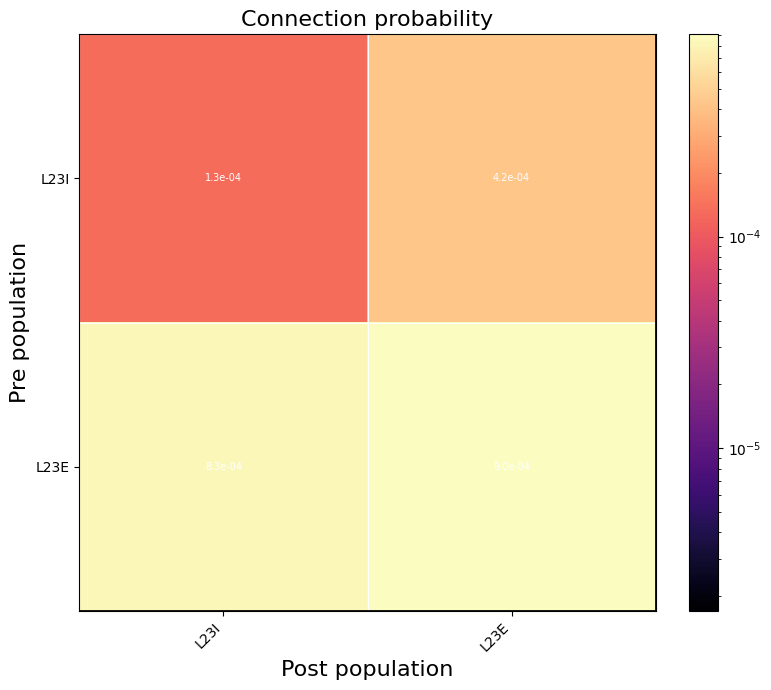

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# -----------------------------
# Population order
# -----------------------------
pop_order = [
    "L23I", "L23E",
]

# -----------------------------
# Build matrix
# -----------------------------
conn_matrix = (
    conn_prob
    .pivot(index="pre", columns="post", values="prob")
    .reindex(index=pop_order, columns=pop_order)
    .fillna(0.0)
)

data = conn_matrix.values
masked_data = np.ma.masked_where(data == 0, data)

vmin = conn_prob.loc[conn_prob["prob"] > 0, "prob"].min()
vmax = conn_prob["prob"].max()

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.magma.copy()
cmap.set_bad(color="lightgray")

im = ax.imshow(
    masked_data,
    cmap=cmap,
    norm=LogNorm(vmin=vmin, vmax=vmax),
    aspect="equal"
)

# -----------------------------
# Axis ticks
# -----------------------------
ax.set_xticks(np.arange(len(pop_order)))
ax.set_yticks(np.arange(len(pop_order)))

ax.set_xticklabels(pop_order, rotation=45, ha="right")
ax.set_yticklabels(pop_order)

ax.set_xlabel("Post population", fontsize = 16)
ax.set_ylabel("Pre population", fontsize = 16)
ax.set_title("Connection probability", fontsize = 16)

ax.set_xticks(np.arange(-0.5, len(pop_order), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(pop_order), 1), minor=True)

ax.grid(which="minor", color="white", linestyle="-", linewidth=0.8)

ax.tick_params(which="minor", bottom=False, left=False)

layer_boundaries = [1.5]

for boundary in layer_boundaries:
    ax.axhline(boundary, color="black", linewidth=2.0)
    ax.axvline(boundary, color="black", linewidth=2.0)

# -----------------------------
# Add values inside cells
# -----------------------------
for i in range(len(pop_order)):
    for j in range(len(pop_order)):
        value = conn_matrix.iloc[i, j]

        if value == 0:
            ax.text(j, i, "0", ha="center", va="center",
                    color="black", fontsize=8)
        else:
            ax.text(j, i, f"{value:.1e}", ha="center", va="center",
                    color="white", fontsize=7)

# -----------------------------
# Colorbar
# -----------------------------
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
#plt.savefig('Connection_Probability_full.png', format='png', dpi=100)
plt.show()

Text(0.5, 0, 'Distance (um)')

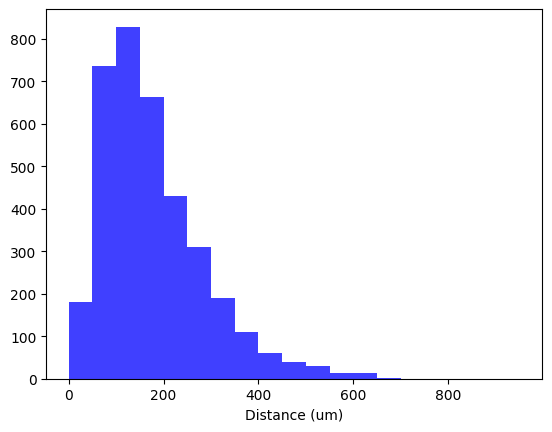

In [31]:
distance = index_pre_post[index_pre_post['population conn'] == 'L23E->L23E']['distance'].reset_index(drop=True)
plt.hist(distance, bins=range(0, 1000, 50), density=False, alpha=0.75, color='b', label='L23E->L23E')
plt.xlabel('Distance (um)')

In [32]:
import numpy as np3
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# --------------------------------------------------
# User controls
# --------------------------------------------------
bin_width = 50  # µm

pop_order = [
    # "L1I", "L1E",
    "L23I", "L23E",
    # "L4I", "L4E",
    # "L5I", "L5E",
    # "L6I", "L6E"
]

# --------------------------------------------------
# 1. Make sure the connection dataframe is binary
# --------------------------------------------------
# This avoids counting multiple synapses between the same pair
# as multiple connections.
index_pre_post_binary = (
    index_pre_post
    .drop_duplicates(subset=["pre", "post"])
    .copy()
)

# --------------------------------------------------
# 2. Use only population pairs with nonzero probability
# --------------------------------------------------
nonzero_pairs = conn_prob[conn_prob["prob"] > 0].copy()

# Optional, keep only populations that are in pop_order
nonzero_pairs = nonzero_pairs[
    nonzero_pairs["pre"].isin(pop_order) &
    nonzero_pairs["post"].isin(pop_order)
].copy()

# --------------------------------------------------
# 3. Global distance bins
# --------------------------------------------------
all_pos = ind_cell_df[["x_new", "y_new", "z_new"]].values.astype(float)

# A simple safe maximum distance
# You can also set this manually, for example dmax = 1000
dmax = np.linalg.norm(all_pos.max(axis=0) - all_pos.min(axis=0))

bins = np.arange(0, dmax + bin_width, bin_width)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

# --------------------------------------------------
# 4. Compute P(connection | distance) for all population pairs
# --------------------------------------------------
distance_prob_rows = []

for _, row in nonzero_pairs.iterrows():

    pop_pre = row["pre"]
    pop_post = row["post"]

    # Neurons from each population
    pre_cells = ind_cell_df[ind_cell_df["mtype"] == pop_pre]
    post_cells = ind_cell_df[ind_cell_df["mtype"] == pop_post]

    pre_indices = pre_cells.index.values
    post_indices = post_cells.index.values

    if len(pre_indices) == 0 or len(post_indices) == 0:
        continue

    pre_pos = pre_cells[["x_new", "y_new", "z_new"]].values.astype(float)
    post_pos = post_cells[["x_new", "y_new", "z_new"]].values.astype(float)

    # --------------------------------------------------
    # Possible distances
    # --------------------------------------------------
    D_possible = cdist(pre_pos, post_pos)

    # Remove autapses for same population
    if pop_pre == pop_post:
        mask = pre_indices[:, None] != post_indices[None, :]
        possible_distances = D_possible[mask]
    else:
        possible_distances = D_possible.ravel()

    possible_counts, _ = np.histogram(possible_distances, bins=bins)

    # --------------------------------------------------
    # Connected distances
    # --------------------------------------------------
    connected_block = index_pre_post_binary[
        (index_pre_post_binary["mtype pre"] == pop_pre) &
        (index_pre_post_binary["mtype post"] == pop_post)
    ].copy()

    connected_distances = connected_block["distance"].values.astype(float)

    connected_counts, _ = np.histogram(connected_distances, bins=bins)

    # --------------------------------------------------
    # Probability and densities
    # --------------------------------------------------
    prob_distance = np.full_like(bin_centers, np.nan, dtype=float)

    valid = possible_counts > 0
    prob_distance[valid] = connected_counts[valid] / possible_counts[valid]

    connected_density = np.full_like(bin_centers, np.nan, dtype=float)
    possible_density = np.full_like(bin_centers, np.nan, dtype=float)

    if connected_counts.sum() > 0:
        connected_density = connected_counts / connected_counts.sum()

    if possible_counts.sum() > 0:
        possible_density = possible_counts / possible_counts.sum()

    for k in range(len(bin_centers)):
        distance_prob_rows.append({
            "mtype pre": pop_pre,
            "mtype post": pop_post,
            "population conn": f"{pop_pre}->{pop_post}",
            "bin_start": bins[k],
            "bin_end": bins[k + 1],
            "bin_center": bin_centers[k],
            "connected_counts": connected_counts[k],
            "possible_counts": possible_counts[k],
            "prob_connection_given_distance": prob_distance[k],
            "connected_density": connected_density[k],
            "possible_density": possible_density[k],
            "original_pair_probability": row["prob"]
        })

distance_prob_df = pd.DataFrame(distance_prob_rows)

distance_prob_df.head(5)

,mtype pre,mtype post,population conn,bin_start,bin_end,bin_center,connected_counts,possible_counts,prob_connection_given_distance,connected_density,possible_density,original_pair_probability
0,L23E,L23E,L23E->L23E,0.0,50.0,25.0,181,10768,0.016809,0.050139,0.006629,0.000904
1,L23E,L23E,L23E->L23E,50.0,100.0,75.0,737,57846,0.012741,0.204155,0.035612,0.000904
2,L23E,L23E,L23E->L23E,100.0,150.0,125.0,829,107880,0.007684,0.229640,0.066414,0.000904
3,L23E,L23E,L23E->L23E,150.0,200.0,175.0,664,136414,0.004868,0.183934,0.083981,0.000904
4,L23E,L23E,L23E->L23E,200.0,250.0,225.0,430,147248,0.002920,0.119114,0.090650,0.000904


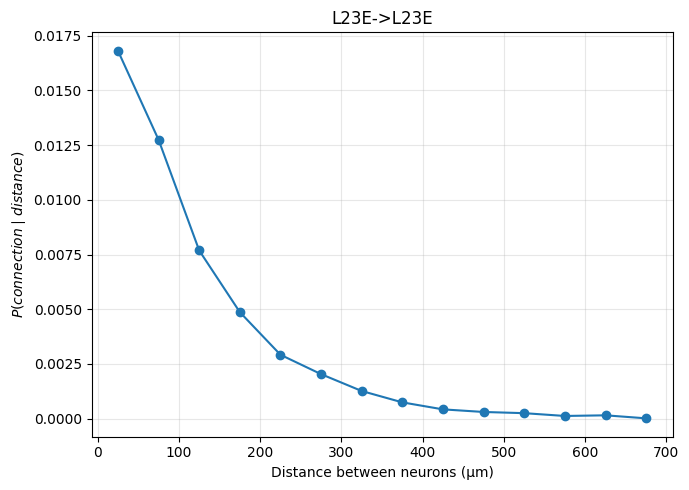

In [33]:
pop_conn = "L23E->L23E"
# pop_conn = "L23E->L4E"

df_plot = distance_prob_df[
    distance_prob_df["population conn"] == pop_conn
].copy()

df_plot = df_plot[
    (df_plot["possible_counts"] > 0) &
    (df_plot["prob_connection_given_distance"] > 0)
]

plt.figure(figsize=(7, 5))

plt.plot(
    df_plot["bin_center"],
    df_plot["prob_connection_given_distance"],
    "o-"
)

plt.xlabel("Distance between neurons (µm)")
plt.ylabel(r"$P(connection \mid distance)$")
plt.title(pop_conn)
#plt.yscale("log")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
from scipy.optimize import curve_fit

x_col = "bin_center"
y_col = "prob_connection_given_distance"

pop_conn = "L23I->L23E"
sub = distance_prob_df[distance_prob_df['population conn'] == pop_conn].copy()

x = sub[x_col].values.astype(float)
y =sub[y_col].values.astype(float)

# Keep only valid positive values
mask = np.isfinite(x) & np.isfinite(y) & (y > 0)

x = x[mask]
y = y[mask]

# Sort by x, useful for plotting
order = np.argsort(x)
x = x[order]
y = y[order]

# --------------------------------------------------
# Define models
# --------------------------------------------------
def exponential_model(d, A, lamb):
    return A * np.exp(-d / lamb)

def gaussian_model(d, A, sigma):
    return A * np.exp(-(d**2) / (2 * sigma**2))

# --------------------------------------------------
# Fit models
# --------------------------------------------------
popt_exp, pcov_exp = curve_fit(
    exponential_model,
    x,
    y,
    p0=[y.max(), 200],
    bounds=([0, 1e-9], [np.inf, np.inf]),
    maxfev=10000
)

popt_gauss, pcov_gauss = curve_fit(
    gaussian_model,
    x,
    y,
    p0=[y.max(), 200],
    bounds=([0, 1e-9], [np.inf, np.inf]),
    maxfev=10000
)

A_exp, lambda_exp = popt_exp
A_gauss, sigma_gauss = popt_gauss

# --------------------------------------------------
# Goodness of fit
# --------------------------------------------------
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

y_exp = exponential_model(x, *popt_exp)
y_gauss = gaussian_model(x, *popt_gauss)

r2_exp = r2_score(y, y_exp)
r2_gauss = r2_score(y, y_gauss)

rmse_exp = rmse(y, y_exp)
rmse_gauss = rmse(y, y_gauss)

# Log-space comparison, usually better for probabilities
log_y = np.log(y)
log_y_exp = np.log(y_exp)
log_y_gauss = np.log(y_gauss)

r2_log_exp = r2_score(log_y, log_y_exp)
r2_log_gauss = r2_score(log_y, log_y_gauss)

rmse_log_exp = rmse(log_y, log_y_exp)
rmse_log_gauss = rmse(log_y, log_y_gauss)

# --------------------------------------------------
# Print results
# --------------------------------------------------
print("Exponential fit:")
print(f"A      = {A_exp:.6e}")
print(f"lambda = {lambda_exp:.3f} µm")
print(f"R²     = {r2_exp:.4f}")
print(f"RMSE   = {rmse_exp:.6e}")
print(f"log R² = {r2_log_exp:.4f}")
print(f"log RMSE = {rmse_log_exp:.4f}")

print("\nGaussian fit:")
print(f"A      = {A_gauss:.6e}")
print(f"sigma  = {sigma_gauss:.3f} µm")
print(f"R²     = {r2_gauss:.4f}")
print(f"RMSE   = {rmse_gauss:.6e}")
print(f"log R² = {r2_log_gauss:.4f}")
print(f"log RMSE = {rmse_log_gauss:.4f}")


Exponential fit:
A      = 3.729900e-02
lambda = 96.018 µm
R²     = 0.9909
RMSE   = 8.026020e-04
log R² = 0.9704
log RMSE = 0.3558

Gaussian fit:
A      = 2.810513e-02
sigma  = 91.191 µm
R²     = 0.9903
RMSE   = 8.300992e-04
log R² = -12.5402
log RMSE = 7.6038


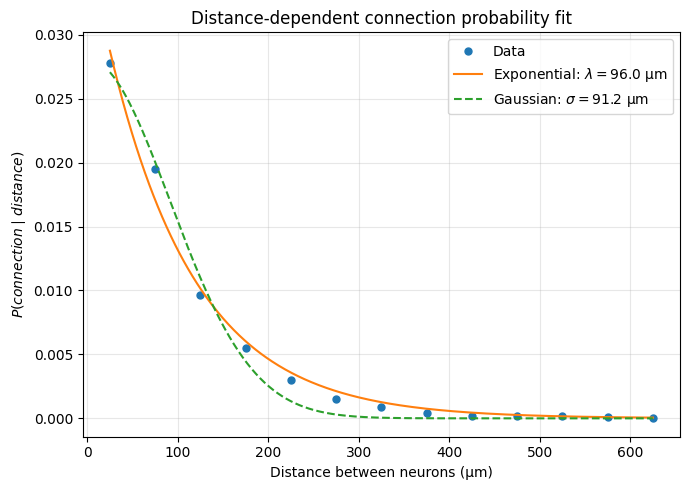

In [35]:
# --------------------------------------------------
# Plot data and fits
# --------------------------------------------------
d_plot = np.linspace(x.min(), x.max(), 500)

plt.figure(figsize=(7, 5))

plt.plot(
    x,
    y,
    "o",
    label="Data",
    markersize=5
)

plt.plot(
    d_plot,
    exponential_model(d_plot, *popt_exp),
    "-",
    label=fr"Exponential: $\lambda={lambda_exp:.1f}$ µm"
)

plt.plot(
    d_plot,
    gaussian_model(d_plot, *popt_gauss),
    "--",
    label=fr"Gaussian: $\sigma={sigma_gauss:.1f}$ µm"
)

plt.xlabel("Distance between neurons (µm)")
plt.ylabel(r"$P(connection \mid distance)$")
#plt.yscale("log")
plt.title("Distance-dependent connection probability fit")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
# type	connections
# EE	96193
# EI	18429
# IE	12973
# II	5463
